# Temporal Distribution Shift Analysis

Chọn kernel `.conda-py311` trong VS Code. Notebook đọc kết quả từ lượt full test chính thức. Đặt `rerun = True` để chạy phân tích vào thư mục mới.

In [1]:
from datetime import datetime
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
root = next(p for p in (cwd, *cwd.parents, cwd / "network-anomaly-hybrid-vscode")
            if (p / "src/drift_detection.py").is_file())
out = root / "outputs/temporal_drift"
rerun = False
if rerun:
    out = out / datetime.now().strftime("rerun_%Y%m%d_%H%M%S_%f")
    subprocess.run([sys.executable, "-X", "utf8", "-m", "src.drift_detection", "--output", str(out)],
                   cwd=root, check=True)
report = out / "drift_report.md"
if report.exists():
    display(Markdown(report.read_text(encoding="utf-8")))

# Temporal Distribution Shift Analysis

Phân tích dùng model, preprocessing, threshold và predictions của lượt full test chính thức `test100_20261109_233550_850520`. Đọc lại toàn bộ **4.653.501 predictions** từ 7 ngày. Nhãn, số dòng theo ngày và cờ Ensemble khớp nguồn. Confusion counts, Recall, FPR, Precision, ROC-AUC và PR-AUC của **21 cặp ngày–mô hình** khớp kết quả tính độc lập của lượt chính thức.

## Phép đo và cách lấy mẫu

- Feature drift đo trên **46 feature model thực sự dùng**, ở thang signed-log và z-score trước clipping với thống kê Train đã lưu. Dùng 50.000 Benign lấy mẫu đều không hoàn lại theo từng ngày, với seed 42 và thứ tự file cố định. Tham chiếu Train gồm 50.000 dòng gộp từ 14–15/02 theo tỷ lệ Benign từng ngày. Tham chiếu Validation là mẫu 50.000 dòng ngày 16/02. `analysis_config.json` ghi số dòng nguồn, file và hash của vị trí mẫu.
- KS là khoảng cách cực đại giữa hai CDF thực nghiệm. Wasserstein-1 giữ thông tin độ lớn trên thang z-score. PSI dùng các phân vị tham chiếu, gộp cạnh trùng, giữ bin ngoài miền và làm trơn 0,5 count mỗi bin. PSI phụ thuộc cách chia bin. KS dùng như kích thước hiệu ứng mô tả, không diễn giải p-value vì nhiều giá trị trùng và flow có thể phụ thuộc nhau. [SciPy KS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html) · [SciPy Wasserstein-1](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html)
- Reconstruction MSE theo feature được đo **sau clipping** trên chính mẫu Benign. Score Train và Validation được tái tính trên mẫu bằng model và Ensemble normalization đã lưu. Score và hiệu năng test dùng toàn bộ predictions, với ngưỡng gốc. FPR của mẫu Validation chỉ dùng mô tả phân phối, còn FPR hiệu chuẩn gốc đến từ 446.619 Benign Validation.
- Attack score được so với Benign tham chiếu để đo độ tách phân phối. Chênh lệch này chứa cả khác biệt nhãn và thời gian. PR-AUC cần đọc cùng tỷ lệ Attack từng ngày.

## Feature shift mạnh nhất

| Feature | KS trung vị qua 7 ngày so với Train | PSI trung vị | Wasserstein trung vị |
|---|---:|---:|---:|
| `rst_flag_count` | 0,13268 | 0,14767 | 0,48057 |
| `fwd_iat_total` | 0,12354 | 0,08725 | 0,19187 |
| `flow_duration` | 0,11732 | 0,09224 | 0,16563 |
| `fwd_iat_min` | 0,11516 | 0,08229 | 0,14843 |
| `flow_packets_s` | 0,10584 | 0,10025 | 0,15083 |

**21/02 nổi bật so với Train.** KS trung vị qua 46 feature đạt **0,56784**, so với **0,11202** ở ngày test kế tiếp 02/03. PSI và Wasserstein trung vị của 21/02 cũng cao nhất trong bảy ngày khi lấy Train làm chuẩn. Cực trị trên ngày này gồm `init_fwd_win_bytes` KS **0,992**, `fwd_packet_length_std` **0,988** và `fwd_packet_length_mean` **0,975**.

**Tham chiếu làm thay đổi cách đọc drift.** Benign Validation đã lệch so với Train với KS trung vị **0,61998**. So với Validation, 21/02 có KS và PSI trung vị lớn nhất trong test (**0,67221** và **5,67875**), nhưng Wasserstein trung vị của ngày này chỉ **0,14464**, thấp nhất trong test. Một CDF có thể khác mạnh tại một điểm dù khoảng dịch chuyển trung bình nhỏ. Vì thế báo cáo ghi cả ba phép đo và tham chiếu.

Kiểm tra độ nhạy lấy mẫu với seed 43 trên cùng model và dữ liệu giữ nguyên cả năm feature đứng đầu. Tương quan Spearman của thứ hạng 46 feature giữa hai seed là **0,9946**. Ngày 21/02 vẫn đứng đầu với KS trung vị **0,56837**. CSV hiệu năng và attack giống hệt vì dùng toàn bộ predictions trong cả hai lượt. Xem `sample_stability.json`.

## Drift và hiệu năng

- **21/02 có bằng chứng xếp hạng kém:** ROC-AUC IF, AE và Ensemble lần lượt **0,01672**, **0,00883** và **0,00886**. PR-AUC **0,20760–0,21344** thấp hơn tỷ lệ Attack **35,73%**. Median AE của Attack **0,01044** thấp hơn Benign **0,07641**. Cả ba bỏ sót toàn bộ HOIC, dù AE và Ensemble vẫn phát hiện phần lớn nhóm LOIC-UDP nhỏ hơn.
- **Drift lớn không đi cùng FPR lớn nhất.** Ngày 21/02, IF có FPR **0,5355%**, thấp nhất trong test. IF đạt FPR cao nhất **5,4365%** vào 28/02 và **5,2652%** vào 01/03, với p99 Benign khoảng **0,63978** ở cả hai ngày, cao hơn threshold **0,58343**. Ensemble đạt FPR cao nhất **1,2611%** ngày 01/03, với p99 Benign **5,24655** cao hơn threshold **5,18523**. Tương quan Spearman giữa KS feature trung vị so với Train và FPR qua bảy ngày là **−0,357** cho IF, **−0,482** cho AE và **−0,429** cho Ensemble. Đây là mô tả trên bảy điểm quan sát.
- **Ranking tốt vẫn có Recall thấp ở ngưỡng hiện tại.** AE ngày 20/02 có ROC-AUC **0,96122**, PR-AUC **0,93689** và Recall **0,1368%**. Ngày 02/03, AE đạt ROC-AUC **0,95150**, PR-AUC **0,64446** và Recall **0%**. Benign AE score lệch mạnh so với Validation ở cả bảy ngày (KS **0,952–0,984**), nhưng FPR AE test cao nhất chỉ **0,1571%**. KS phản ánh toàn phân phối, còn FPR phụ thuộc phần đuôi trên threshold.

## Drift feature và reconstruction error

Ngày 21/02, ba feature drift lớn nhất khác với ba feature có MSE tái tạo cao nhất: `bwd_iat_std` (**0,894**), `rst_flag_count` (**0,331**) và `active_mean` (**0,297**). Spearman giữa KS và MSE theo 46 feature là **0,128** hôm đó, dao động **−0,007 đến 0,200** qua bảy ngày khi lấy Train làm chuẩn. Spearman giữa KS và mức tăng MSE so với Train cũng nhỏ (**−0,065 đến 0,175**). Các phép đo chưa hỗ trợ kết luận rằng feature drift mạnh nhất là feature có lỗi tái tạo cao nhất. Clipping và cách AE học tương tác giữa các feature có thể ảnh hưởng mối liên hệ này, nhưng thí nghiệm chưa cô lập hai cơ chế đó.

## Các nhóm tấn công trọng tâm

| Nhãn nguồn | Số flow | TP IF | TP AE | TP Ensemble |
|---|---:|---:|---:|---:|
| DDOS attack-HOIC | 198.861 | 0 | 0 | 0 |
| DDoS attacks-LOIC-HTTP | 575.364 | 85 | 787 | 786 |
| Bot | 144.535 | 990 | 0 | 116 |
| Infilteration | 118.483 | 7.642 | 0 | 787 |

HOIC và LOIC-HTTP chiếm phần lớn Attack nhưng Recall rất thấp. IF nhận diện **6,4499%** Infilteration, trong khi Ensemble nhận diện **0,6642%**. `attack_analysis.csv` lưu score quantiles, TP/FN và Recall theo loại/ngày; các dòng theo loại chỉ có mẫu dương nên không tính FPR.

## Kết luận có thể rút ra

Dữ liệu xác nhận thay đổi phân phối Benign feature, thay đổi score và thay đổi điểm vận hành theo ngày dưới cùng model. Kết quả xác nhận cả hai trường hợp: ranking suy giảm mạnh vào 21/02, và ranking vẫn tốt nhưng Recall thấp ở ngưỡng hiện tại vào 20/02 và 02/03. Mối liên hệ phụ thuộc ngày, mô hình và nhóm Attack.

Chưa xác nhận concept drift, nguyên nhân thu thập dữ liệu, thay đổi hành vi mạng hoặc chất lượng nhãn. Để kiểm tra những giả thuyết này cần dữ liệu theo phiên/nguồn, kiểm chứng nhãn và phân tích có đối chứng trên các cửa sổ thời gian độc lập. Kết quả test chỉ dùng cho phân tích mô tả.


In [2]:
feature = pd.read_csv(out / "feature_drift_by_day.csv")
performance = pd.read_csv(out / "performance_by_day.csv")
attacks = pd.read_csv(out / "attack_analysis.csv")
display(feature.groupby(["reference", "day"])[["ks", "psi", "wasserstein"]].median())
display(performance)
display(attacks[(attacks.day == "ALL") & attacks.focus])

ks       psi  wasserstein
reference  day                                       
2018-02-16 2018-02-20  0.61507  4.062350     0.875555
           2018-02-21  0.67221  5.678750     0.144640
           2018-02-22  0.58595  3.701682     0.864316
           2018-02-23  0.58187  3.739481     0.876543
           2018-02-28  0.64131  4.093926     0.921077
           2018-03-01  0.63246  3.902466     0.902758
           2018-03-02  0.54178  3.672502     0.809666
train      2018-02-16  0.61998  5.221527     0.883644
           2018-02-20  0.02473  0.007624     0.029010
           2018-02-21  0.56784  5.758719     0.817782
           2018-02-22  0.05957  0.042656     0.105002
           2018-02-23  0.06754  0.046074     0.121024
           2018-02-28  0.06426  0.042875     0.084219
           2018-03-01  0.05198  0.043128     0.076068
           2018-03-02  0.11202  0.091959     0.146058

,day,model,threshold,n,attacks,prevalence,TP,FP,TN,FN,recall,fpr,precision,roc_auc,pr_auc
0,2018-02-20,IF,0.583429,954846,575364,0.602573,85,11681,367801,575279,0.000148,0.030781,0.007224,0.784678,0.708968
1,2018-02-21,IF,0.583429,561396,200591,0.357307,25,1932,358873,200566,0.000125,0.005355,0.012775,0.016723,0.207596
2,2018-02-22,IF,0.583429,830224,341,0.000411,30,21230,808653,311,0.087977,0.025582,0.001411,0.763947,0.000992
3,2018-02-23,IF,0.583429,829405,541,0.000652,195,21413,807451,346,0.360444,0.025834,0.009024,0.833830,0.007447
4,2018-02-28,IF,0.583429,456873,56449,0.123555,3030,21769,378655,53419,0.053677,0.054365,0.122182,0.505027,0.124180
5,2018-03-01,IF,0.583429,249170,62034,0.248963,4612,9853,177283,57422,0.074346,0.052652,0.318839,0.511453,0.263556
6,2018-03-02,IF,0.583429,771587,144535,0.187322,990,20387,606665,143545,0.006850,0.032512,0.046311,0.882728,0.446739
7,2018-02-20,AE,2.077148,954846,575364,0.602573,787,596,378886,574577,0.001368,0.001571,0.569053,0.961217,0.936891
8,2018-02-21,AE,2.077148,561396,200591,0.357307,1730,0,360805,198861,0.008625,0.000000,1.000000,0.008830,0.213444
9,2018-02-22,AE,2.077148,830224,341,0.000411,0,1,829882,341,0.000000,0.000001,0.000000,0.806247,0.004466


,day,attack,model,threshold,focus,FN,n,p10,median,p90,p99,above_threshold,alert_rate
12,ALL,Bot,IF,0.583429,True,143545,144535,0.525151,0.526865,0.529222,0.534610,990,0.006850
15,ALL,DDOS attack-HOIC,IF,0.583429,True,198861,198861,0.483052,0.510657,0.522340,0.527259,0,0.000000
17,ALL,DDoS attacks-LOIC-HTTP,IF,0.583429,True,575279,575364,0.493180,0.496553,0.498887,0.504099,85,0.000148
18,ALL,Infilteration,IF,0.583429,True,110841,118483,0.409564,0.482212,0.566023,0.634548,7642,0.064499
32,ALL,Bot,AE,2.077148,True,144535,144535,0.025266,0.026824,0.029594,0.068227,0,0.000000
35,ALL,DDOS attack-HOIC,AE,2.077148,True,198861,198861,0.009187,0.010415,0.014536,0.017426,0,0.000000
37,ALL,DDoS attacks-LOIC-HTTP,AE,2.077148,True,574577,575364,0.020254,0.053295,0.078176,0.082725,787,0.001368
38,ALL,Infilteration,AE,2.077148,True,118483,118483,0.000185,0.001886,0.039616,0.520126,0,0.000000
52,ALL,Bot,Ensemble,5.185228,True,144419,144535,-1.275544,-1.177570,-1.064449,-0.060453,116,0.000803
55,ALL,DDOS attack-HOIC,Ensemble,5.185228,True,198861,198861,-3.884383,-2.851806,-1.955441,-1.651358,0,0.000000


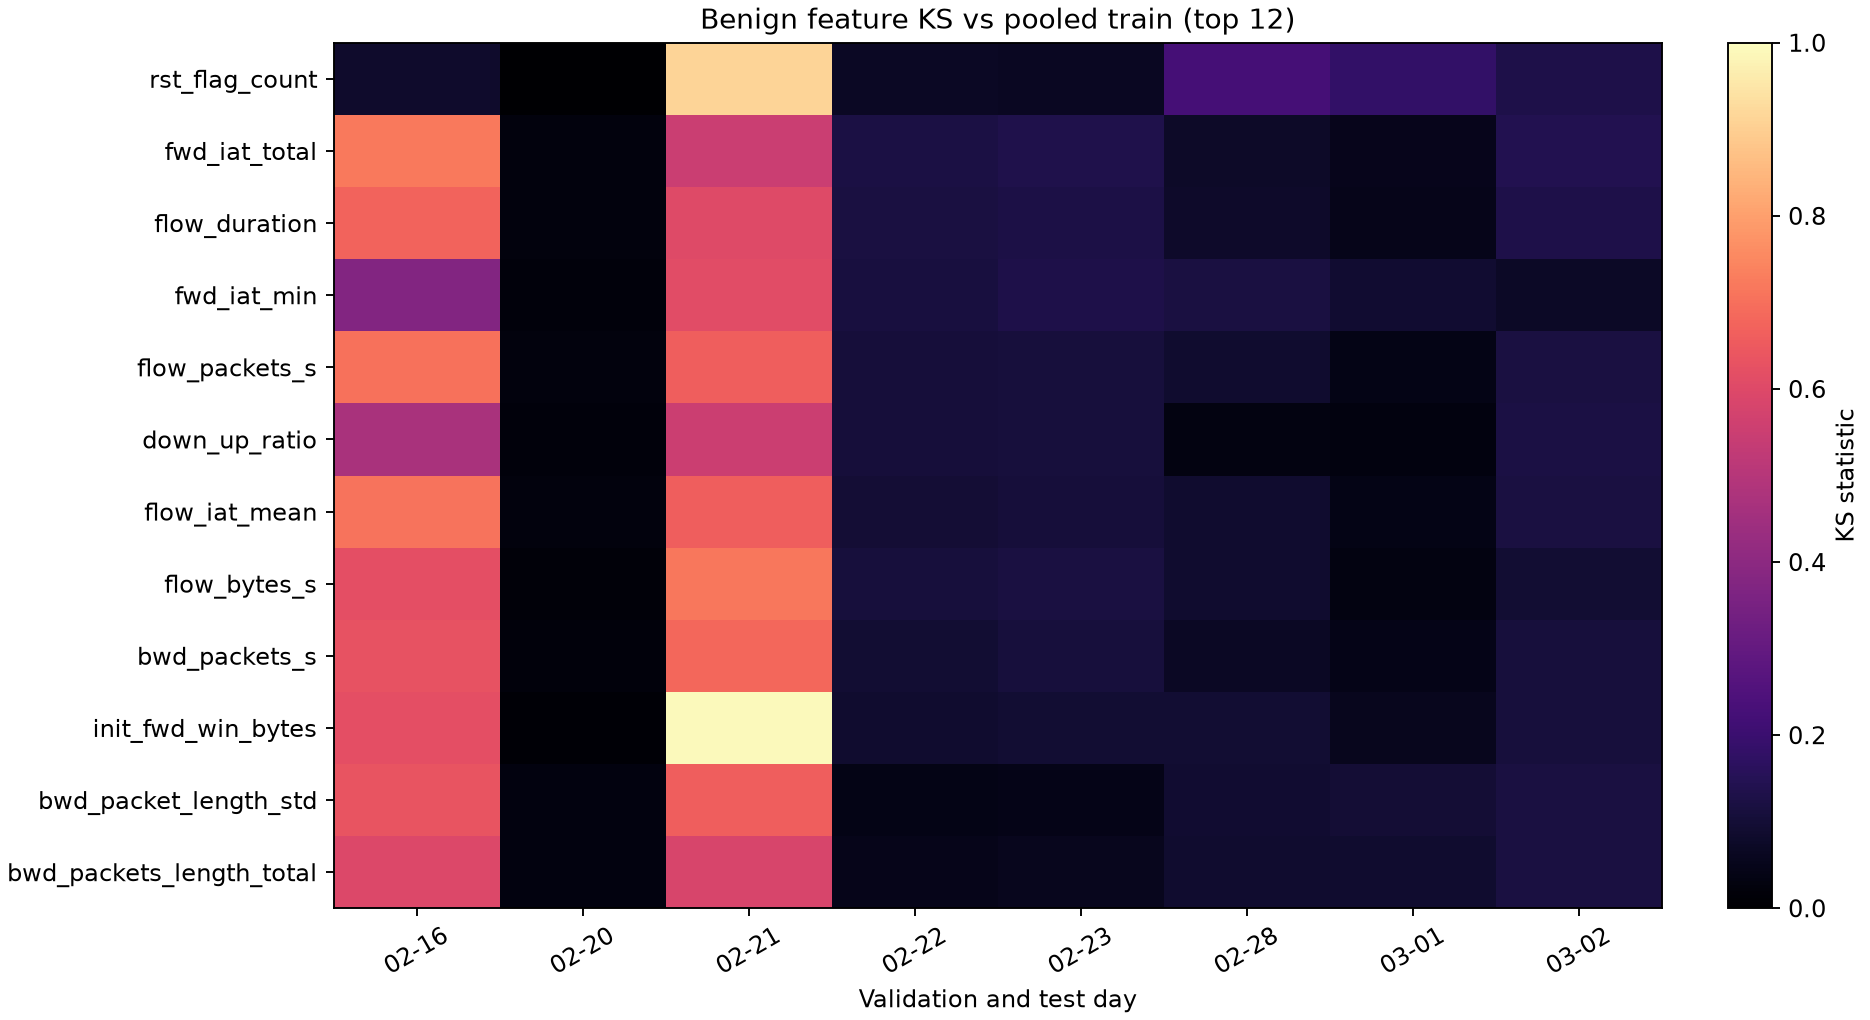

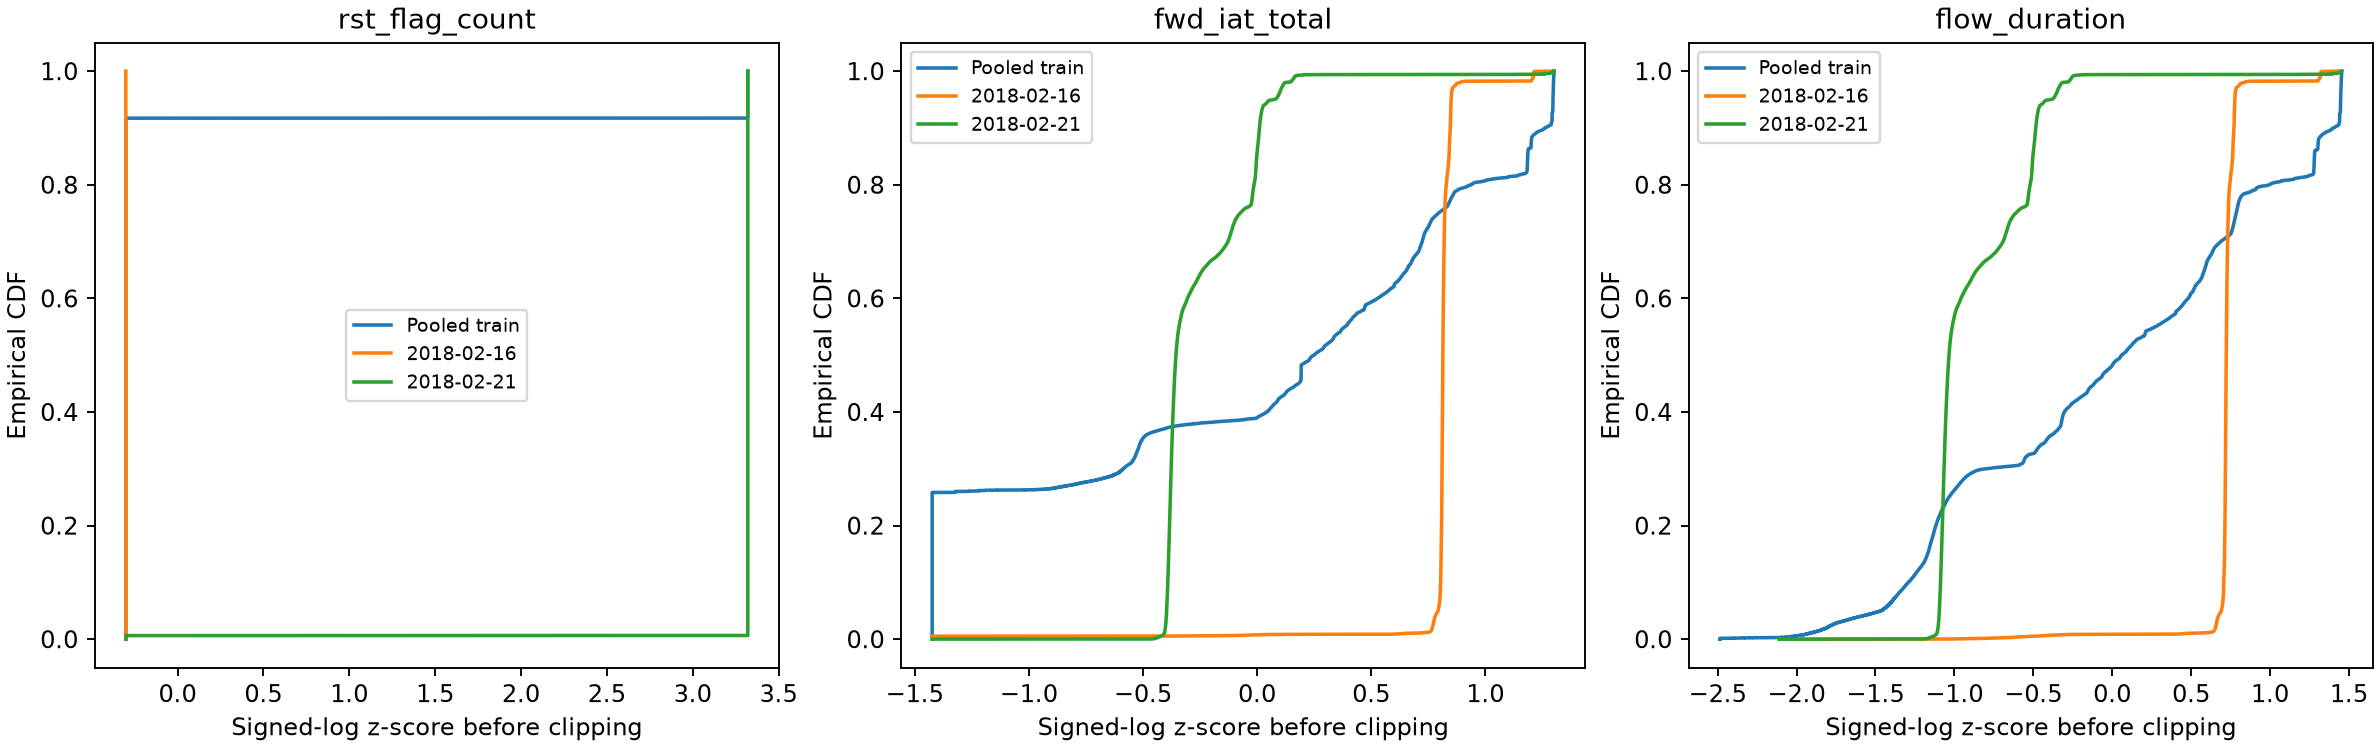

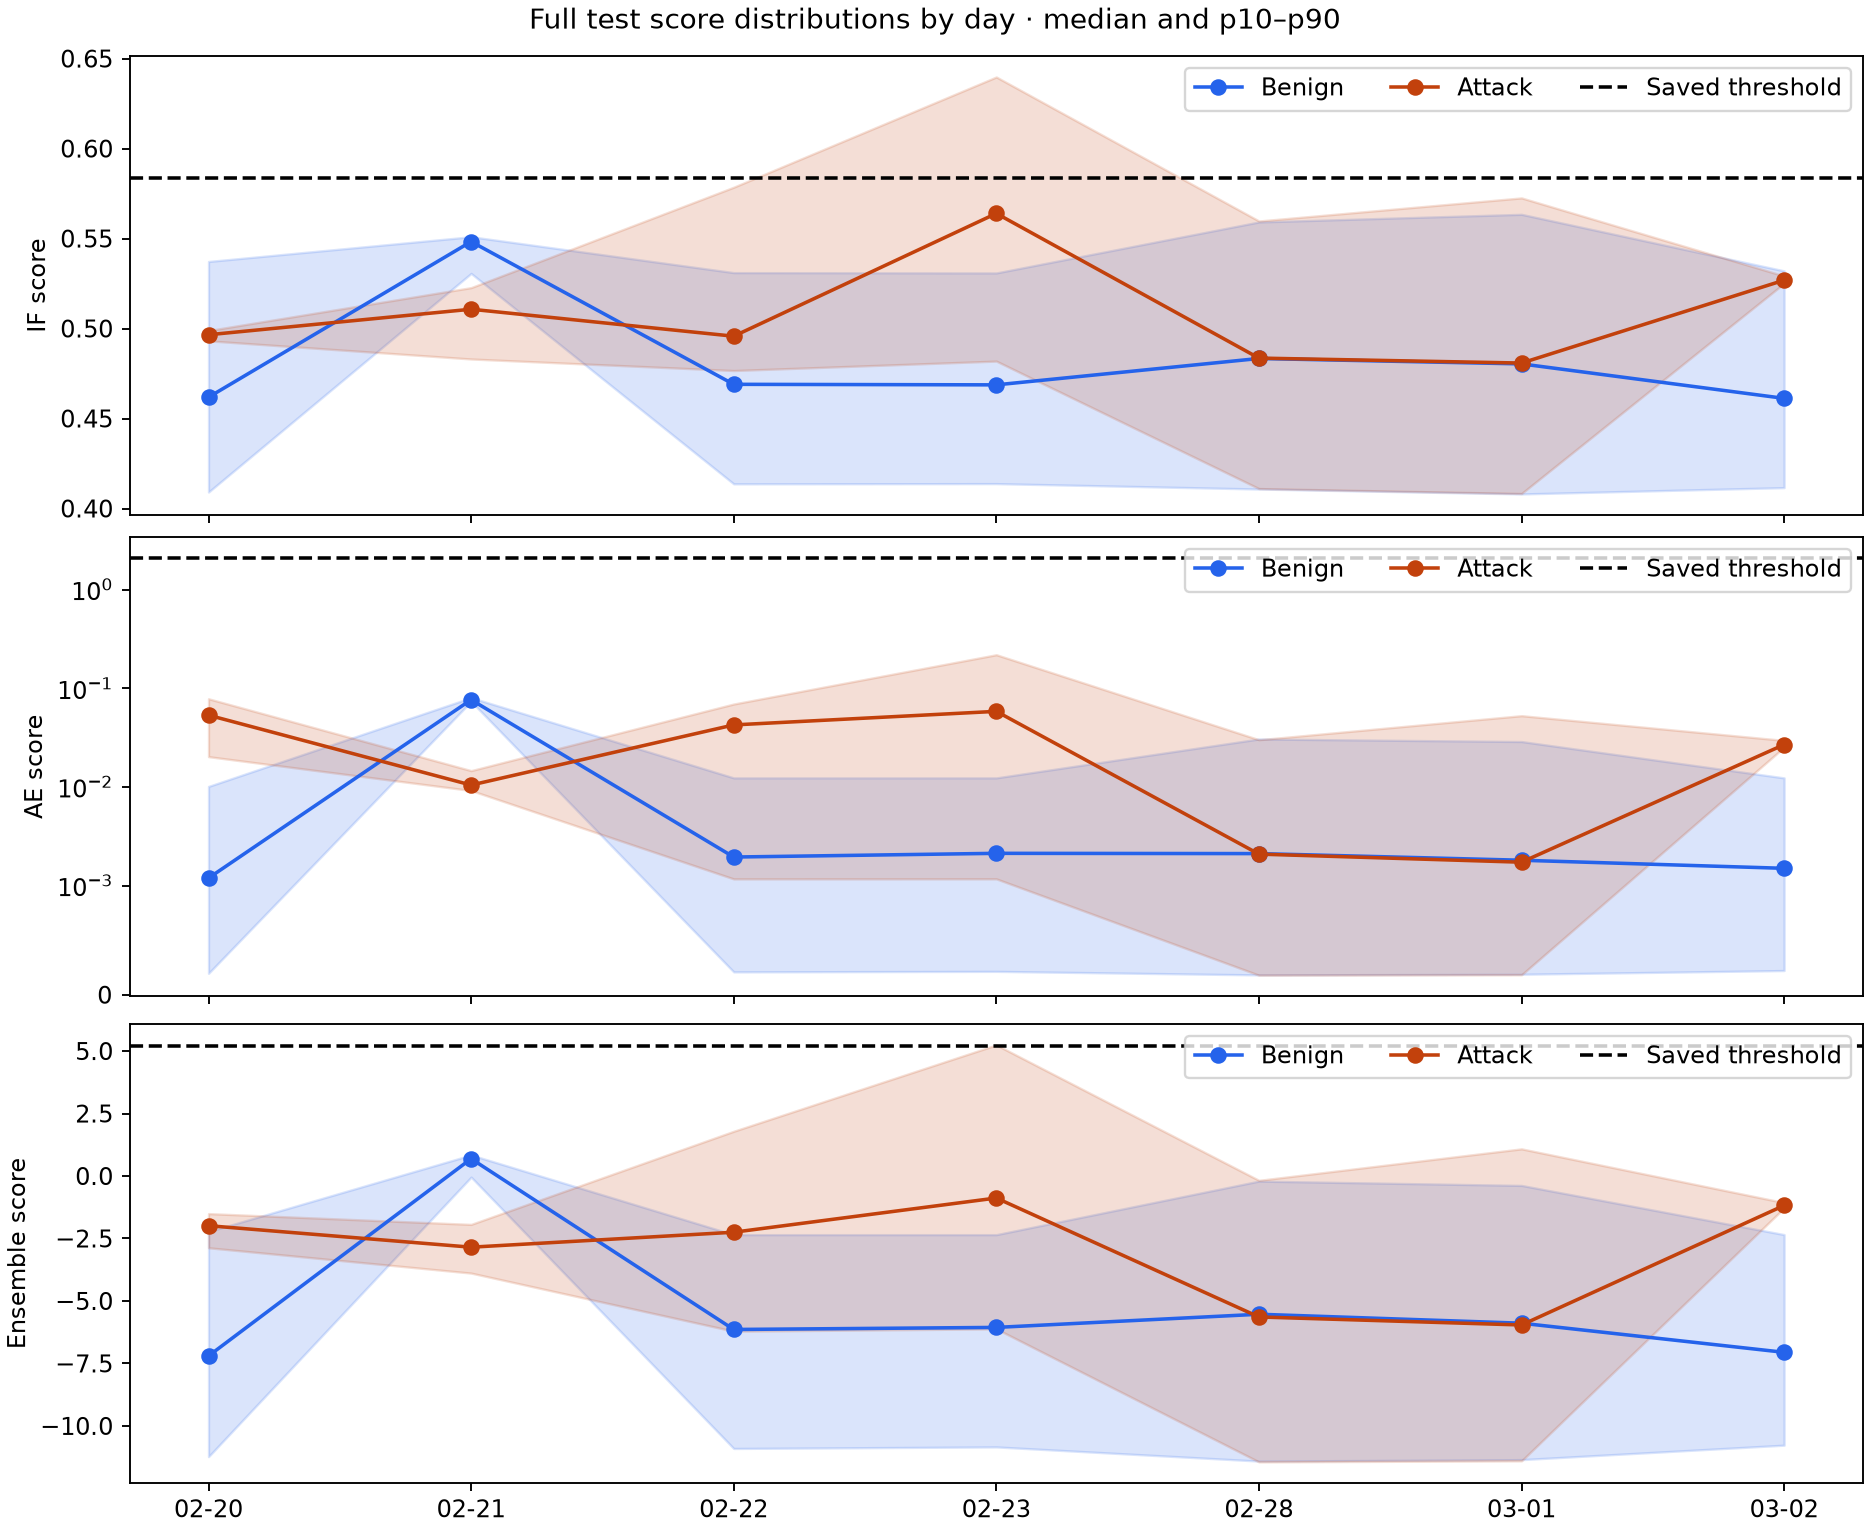

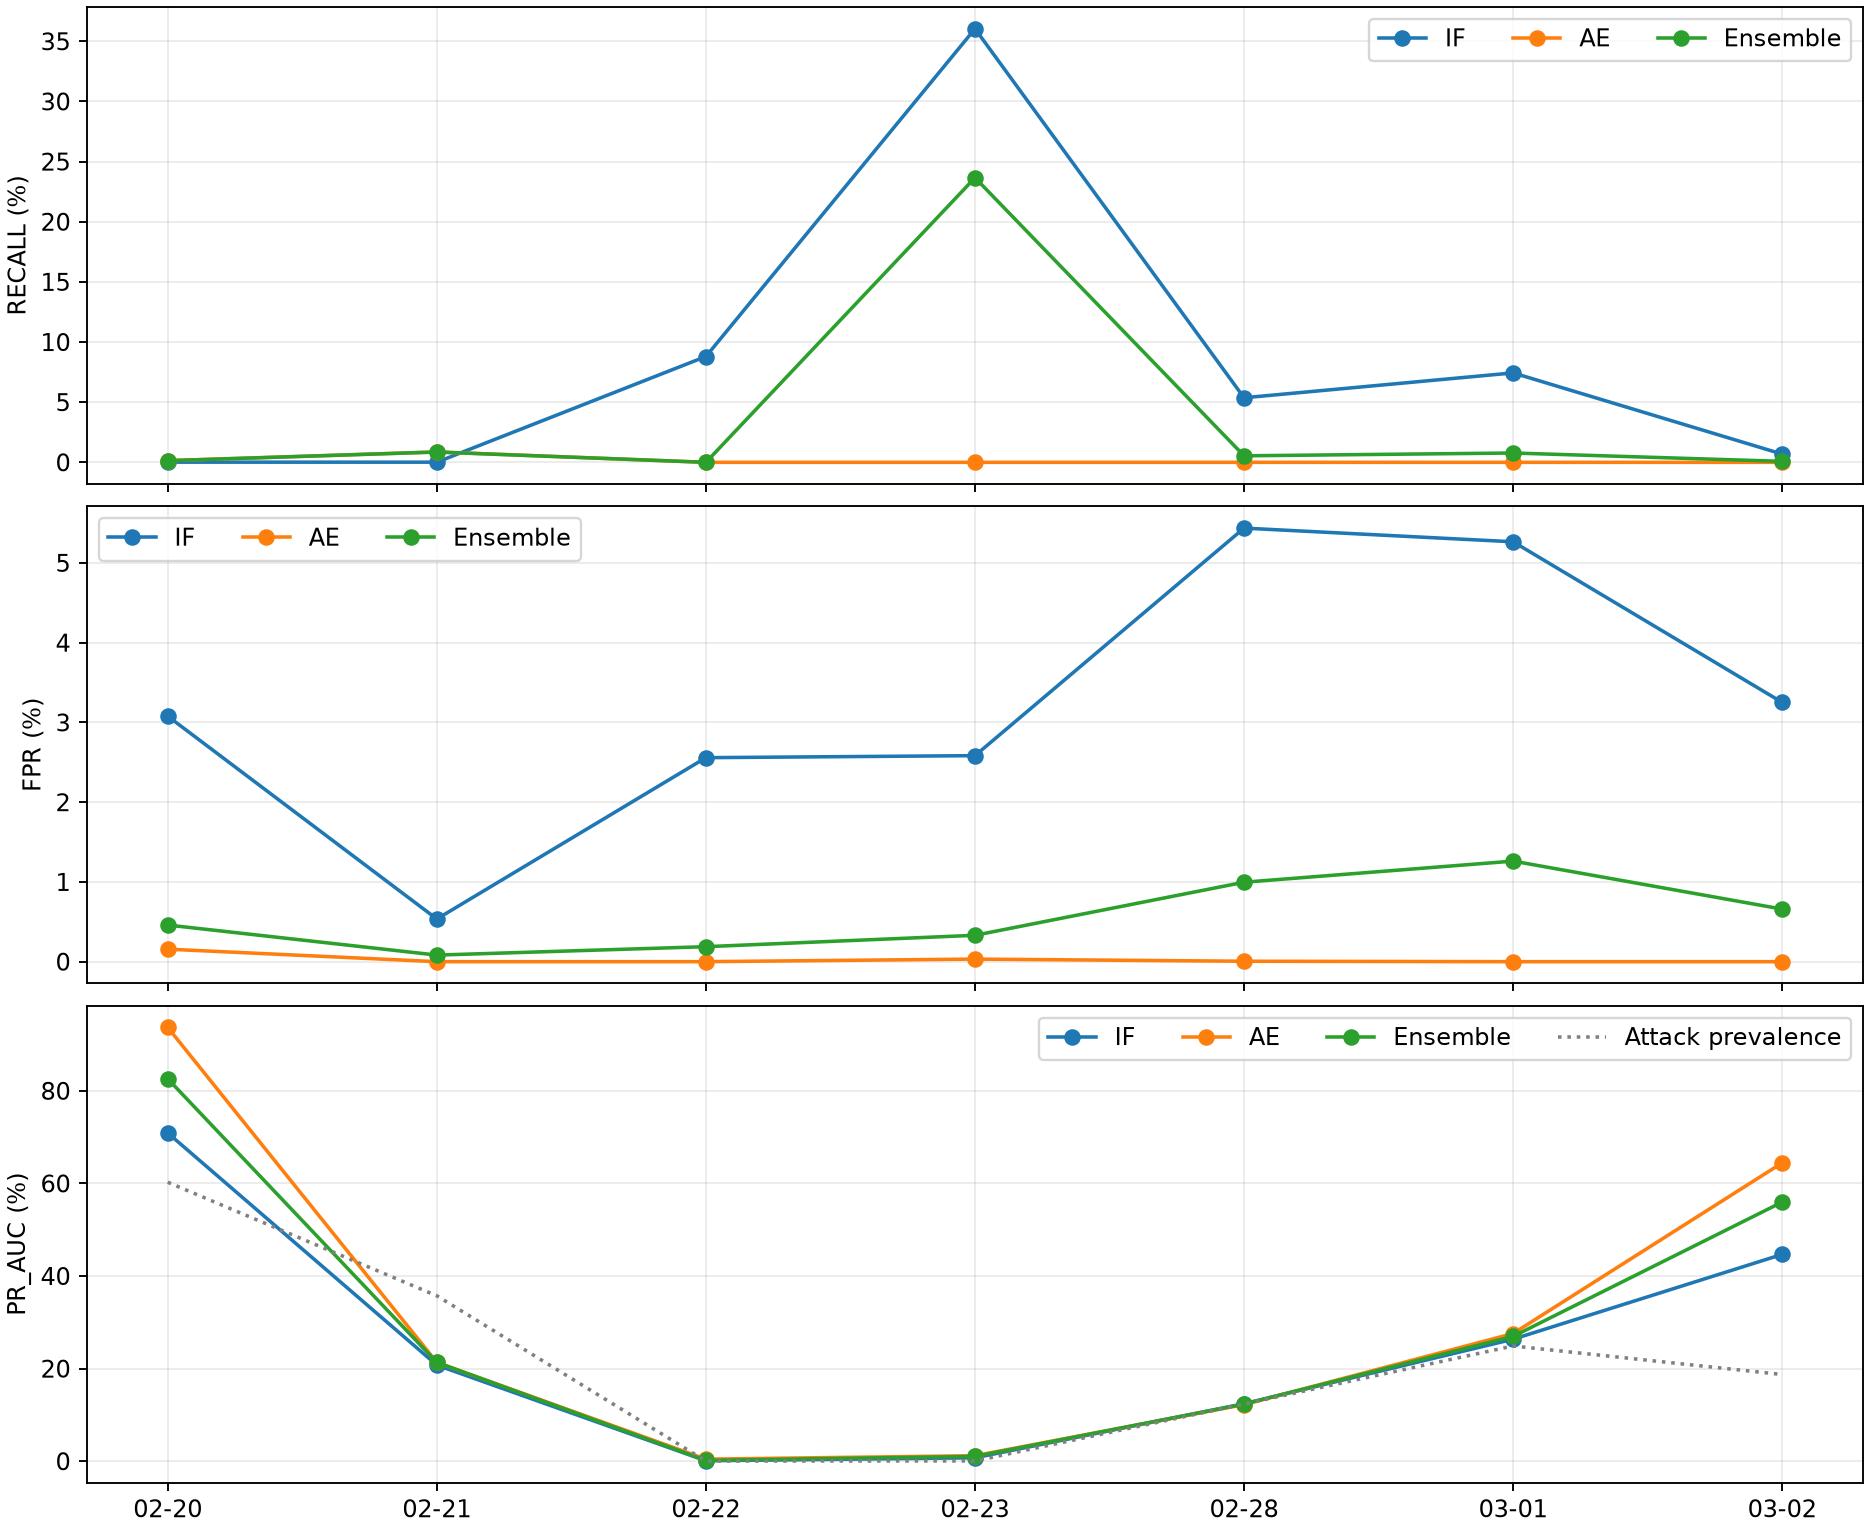

In [3]:
for name in ("feature_drift_heatmap.png", "feature_distributions.png",
             "score_distributions.png", "performance_by_day.png"):
    display(Image(filename=str(out / name)))